# 2. Làm sạch dữ liệu (Data Cleaning)

Notebook 1 đã cho thấy **76% số dòng có ít nhất một ô lỗi** và mọi khách hàng đều có lỗi → không thể xóa dòng, phải *sửa/khôi phục*. Notebook này thực hiện từng quyết định đã rút ra ở EDA, **kiểm chứng định lượng** từng quyết định, và xuất file sạch.

## Quy trình 6 bước

| Bước | Việc làm | Căn cứ (notebook 1) |
|---|---|---|
| 1 | Giá trị giả → NaN | mục 1.4.2 |
| 2 | Bỏ `_` và ép kiểu số | mục 1.4.1 |
| 3 | Giá trị vô lý → NaN | mục 1.5 |
| 4 | Sửa / điền thiếu – **chọn chiến lược bằng thí nghiệm** | mục 1.3, 1.6 |
| 5 | Kiểm tra ràng buộc, báo cáo chất lượng trước/sau | mục 1.9 |
| 6 | Xuất `credit_clean.csv` và báo cáo | – |

## Nguyên tắc
- **Không dùng nhãn `Credit_Score`** ở bất kỳ bước nào (tránh rò rỉ thông tin từ nhãn vào đặc trưng).
- Mỗi bước là một hàm nhỏ, có thể kiểm thử. Mã trong notebook này **trùng nguyên văn** với `src/credit_cleaning.py` (notebook 3 và 4 dùng lại module); cuối notebook có bước kiểm tra hai bên cho kết quả giống hệt.
- Lỗi nào có thể sửa **chính xác** (suy ra bằng luật) thì sửa bằng luật; chỉ khi không thể mới dùng ước lượng – và ước lượng được chọn bằng thí nghiệm chứ không đoán.

In [1]:
import sys, json, re, warnings
sys.path.insert(0, '../src')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.ensemble import HistGradientBoostingRegressor
warnings.filterwarnings('ignore')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})
pd.set_option('display.max_columns', 40); pd.set_option('display.width', 170)

raw = pd.read_csv('../data/train.csv', low_memory=False)
print(f'Dữ liệu gốc: {raw.shape[0]:,} dòng × {raw.shape[1]} cột')
LOG = {}          # nhật ký làm sạch (đếm số ô bị tác động ở từng bước)

Dữ liệu gốc: 100,000 dòng × 28 cột


## Cấu hình – các hằng số rút ra từ EDA
Mỗi hằng số đều có nguồn gốc ở notebook 1 (miền hợp lệ ở 1.5.1, ngưỡng EMI ở 1.5.2, ngưỡng thu nhập ở 1.5.3, danh sách placeholder ở 1.4.2). `REPAIR_PLAN` là kế hoạch sửa lỗi – sẽ được **kiểm chứng ở Bước 4**.

In [2]:
# ----------------------------------------------------------------------------------------------
# Hằng số – rút ra từ EDA (notebook 1)
# ----------------------------------------------------------------------------------------------
MONTHS = ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August']

ID_COLS = ['ID', 'Customer_ID', 'Name', 'SSN']

TARGET = 'Credit_Score'

# Các cột lẽ ra là số nhưng bị lưu thành chữ có ký tự '_' dính vào
NUMERIC_TEXT_COLS = ['Age', 'Annual_Income', 'Num_of_Loan', 'Num_of_Delayed_Payment', 'Changed_Credit_Limit',
                     'Outstanding_Debt', 'Amount_invested_monthly', 'Monthly_Balance']

# Giá trị giả (placeholder) – nhận diện ở EDA mục 1.4
PLACEHOLDERS = {
    'SSN': '#F%$D@*&8',
    'Occupation': '_______',
    'Credit_Mix': '_',
    'Payment_Behaviour': '!@9#%8',
    'Changed_Credit_Limit': '_',
    'Amount_invested_monthly': '__10000__',
    'Monthly_Balance': '__-333333333333333333333333333__',
}

# Miền hợp lệ (đóng) = "thân" phân phối: đoạn giá trị liên tiếp mà mỗi giá trị xuất hiện >= 50 lần (cột đếm: cận dưới >= 0)
# (EDA mục 1.5: phía trên cận này mỗi giá trị chỉ xuất hiện vài lần => nhiễu tiêm vào, không phải phân phối thật)
DOMAIN = {
    'Age': (14, 56),
    'Num_Bank_Accounts': (0, 10),
    'Num_Credit_Card': (1, 10),
    'Interest_Rate': (1, 34),
    'Num_of_Loan': (0, 9),
    'Num_of_Delayed_Payment': (0, 28),
    'Num_Credit_Inquiries': (0, 17),
}

EMI_MAX = 1800  # EMI hợp lệ lớn nhất quan sát được là 1779; mọi số nguyên dương còn lại là nhiễu tiêm

INCOME_REL_TOL = 0.5  # Annual_Income lệch > 50% so với trung vị của chính khách hàng => nhiễu (thu nhập thật không đổi trong 8 tháng)

# Kế hoạch sửa lỗi theo từng cột – chọn bằng thí nghiệm "che 10% giá trị" ở notebook 2
REPAIR_PLAN = {
    'cust_mode':   ['SSN', 'Occupation', 'Name', 'Credit_Mix'],
    'cust_median': ['Annual_Income', 'Interest_Rate', 'Outstanding_Debt',
                    'Num_of_Delayed_Payment', 'Changed_Credit_Limit'],
    'nearest':     ['Num_Bank_Accounts', 'Num_Credit_Card', 'Age', 'Total_EMI_per_month',
                    'Monthly_Inhand_Salary', 'Num_Credit_Inquiries'],
    'model_ratio': ['Amount_invested_monthly', 'Monthly_Balance'],
}

# Các cột làm đặc trưng cho mô hình điền thiếu (không chứa nhãn)
MODEL_IMPUTE_FEATURES = ['Annual_Income', 'Monthly_Inhand_Salary', 'Num_Bank_Accounts', 'Num_Credit_Card',
                         'Interest_Rate', 'Total_EMI_per_month', 'Outstanding_Debt', 'Age',
                         'Num_of_Delayed_Payment', 'Changed_Credit_Limit', 'Num_Credit_Inquiries',
                         'Delay_from_due_date', 'Credit_Utilization_Ratio', 'Amount_invested_monthly',
                         'Monthly_Balance', 'Payment_Behaviour_Code', 'Month_Num']

assert TARGET not in MODEL_IMPUTE_FEATURES      # không bao giờ dùng nhãn khi làm sạch

## Bước 1 – Giá trị giả → NaN
Phải làm **trước** khi bỏ dấu `_`: nếu không, `__10000__` sẽ trở thành số 10000 "trông như thật" (notebook 1, mục 1.4.2). Hàm `add_month_num` thêm số thứ tự tháng (1–8); dữ liệu đã được kiểm tra là sắp đúng thứ tự tháng trong từng khách.

In [3]:
# ----------------------------------------------------------------------------------------------
# Bước 1–2: kiểu dữ liệu và giá trị giả
# ----------------------------------------------------------------------------------------------
def add_month_num(d):
    """Thêm Month_Num (1..8). Dữ liệu được sắp theo (Customer_ID, Month) nên đây cũng là thứ tự thời gian."""
    d = d.copy()
    d['Month_Num'] = d['Month'].map({m: i + 1 for i, m in enumerate(MONTHS)}).astype(int)
    return d

def mark_placeholders(d, log=None):
    """Bước 1: đổi các giá trị giả sang NaN. Phải chạy TRƯỚC strip_numeric_text,
    vì '__10000__' sẽ trở thành số 10000 'trông như thật' nếu chỉ bỏ dấu '_'."""
    d = d.copy()
    for col, token in PLACEHOLDERS.items():
        bad = d[col] == token
        if log is not None:
            log.setdefault('placeholder', {})[col] = int(bad.sum())
        d.loc[bad, col] = np.nan
    return d

d1 = mark_placeholders(add_month_num(raw), LOG)
pd.DataFrame({'số ô → NaN': LOG['placeholder'], '% dòng': {c: round(n / len(raw) * 100, 2) for c, n in LOG['placeholder'].items()}})

,số ô → NaN,% dòng
SSN,5572,5.57
Occupation,7062,7.06
Credit_Mix,20195,20.20
Payment_Behaviour,7600,7.60
Changed_Credit_Limit,2091,2.09
Amount_invested_monthly,4305,4.30
Monthly_Balance,9,0.01


In [4]:
# Minh họa trước / sau (các dòng có placeholder)
i = raw.index[(raw.Amount_invested_monthly == '__10000__') & (raw.Credit_Mix == '_')][:3]
pd.concat({'TRƯỚC': raw.loc[i, ['Credit_Mix', 'Occupation', 'Amount_invested_monthly', 'Payment_Behaviour']],
           'SAU': d1.loc[i, ['Credit_Mix', 'Occupation', 'Amount_invested_monthly', 'Payment_Behaviour']]}, axis=1)

TRƯỚC                                                                                 SAU                                         \
    Credit_Mix     Occupation Amount_invested_monthly                 Payment_Behaviour Credit_Mix     Occupation Amount_invested_monthly   
161          _       Musician               __10000__   High_spent_Large_value_payments        NaN       Musician                     NaN   
484          _  Media_Manager               __10000__    Low_spent_Small_value_payments        NaN  Media_Manager                     NaN   
716          _       Engineer               __10000__  High_spent_Medium_value_payments        NaN       Engineer                     NaN   

                                       
                    Payment_Behaviour  
161   High_spent_Large_value_payments  
484    Low_spent_Small_value_payments  
716  High_spent_Medium_value_payments

## Bước 2 – Bỏ `_` và ép kiểu số
Bỏ dấu `_` ở đầu/cuối rồi ép `float64` (`'24_'` → `24.0`). Notebook 1 (mục 1.4.1) đã chứng minh cách này đọc được 100% ô còn lại.

In [5]:
def strip_numeric_text(d):
    """Bước 2: bỏ dấu '_' ở đầu/cuối rồi ép kiểu số ('24_' -> 24, '14388.79_' -> 14388.79)."""
    d = d.copy()
    for col in NUMERIC_TEXT_COLS:
        txt = d[col].astype('string').str.replace(r'^_+|_+$', '', regex=True)
        d[col] = pd.to_numeric(txt, errors='coerce').astype('float64')   # float64 để NaN hoạt động bình thường
    return d

d2 = strip_numeric_text(d1)
pd.DataFrame({'dtype trước': raw[NUMERIC_TEXT_COLS].dtypes.astype(str), 'dtype sau': d2[NUMERIC_TEXT_COLS].dtypes.astype(str),
              'ví dụ trước': raw[NUMERIC_TEXT_COLS].apply(lambda s: s[s.astype(str).str.contains('_') & (s != '__10000__')].iloc[0] if (s.astype(str).str.contains('_') & (s != '__10000__')).any() else '-'),
              'NaN sau (gồm cả placeholder)': d2[NUMERIC_TEXT_COLS].isna().sum()})

,dtype trước,dtype sau,ví dụ trước,NaN sau (gồm cả placeholder)
Age,str,float64,28_,0
Annual_Income,str,float64,34847.84_,0
Num_of_Loan,str,float64,0_,0
Num_of_Delayed_Payment,str,float64,8_,7002
Changed_Credit_Limit,str,float64,_,2091
Outstanding_Debt,str,float64,1328.93_,0
Amount_invested_monthly,str,float64,-,8784
Monthly_Balance,str,float64,__-333333333333333333333333333__,1209


## Bước 3 – Giá trị vô lý → NaN
Ba luật, mỗi luật có bằng chứng riêng ở notebook 1:
- **(a)** ngoài miền hợp lệ `DOMAIN` (1.5.1) – gồm cả các giá trị giả dạng số `Age = -500`, `Num_of_Loan = -100`;
- **(b)** EMI > 1800 hoặc là số nguyên dương (1.5.2);
- **(c)** `Annual_Income` lệch > 50% so với trung vị của chính khách (1.5.3).

In [6]:
# ----------------------------------------------------------------------------------------------
# Bước 3: giá trị vô lý -> NaN
# ----------------------------------------------------------------------------------------------
def mark_invalid(d, log=None):
    """Bước 3: đánh dấu NaN cho giá trị không thể là dữ liệu thật.
    (a) ngoài miền hợp lệ DOMAIN;  (b) EMI: lớn bất thường hoặc là số nguyên dương
    (EMI thật là số thực dài ~15 chữ số lẻ, số nguyên dương chỉ có ở giá trị nhiễu);
    (c) Annual_Income lệch > 50% so với trung vị của chính khách hàng."""
    d = d.copy()
    log = {} if log is None else log
    inv = log.setdefault('invalid', {})
    for col, (lo, hi) in DOMAIN.items():
        bad = (d[col] < lo) | (d[col] > hi)
        inv[col] = int(bad.sum())
        d.loc[bad, col] = np.nan
    emi = d['Total_EMI_per_month']
    bad = (emi > EMI_MAX) | ((emi > 0) & (emi == emi.round(0)))
    inv['Total_EMI_per_month'] = int(bad.sum())
    d.loc[bad, 'Total_EMI_per_month'] = np.nan
    rel_dev = (d['Annual_Income'] / d.groupby('Customer_ID')['Annual_Income'].transform('median') - 1).abs()
    bad = rel_dev > INCOME_REL_TOL
    inv['Annual_Income'] = int(bad.sum())
    d.loc[bad, 'Annual_Income'] = np.nan
    return d

d3 = mark_invalid(d2, LOG)
inv = pd.Series(LOG['invalid'], name='số ô → NaN').to_frame()
inv['% dòng'] = (inv['số ô → NaN'] / len(raw) * 100).round(2)
inv

,số ô → NaN,% dòng
Age,2781,2.78
Num_Bank_Accounts,1345,1.34
Num_Credit_Card,2320,2.32
Interest_Rate,2034,2.03
Num_of_Loan,4348,4.35
Num_of_Delayed_Payment,1380,1.38
Num_Credit_Inquiries,1650,1.65
Total_EMI_per_month,3164,3.16
Annual_Income,999,1.00


### Kiểm chứng: các ô bị loại có thật sự là rác, và các ô được giữ có thật sự đúng không?
Với các cột *hằng số theo khách* (đã chứng minh ở 1.6), có một "đáp án" độc lập: **giá trị phổ biến nhất của chính khách đó**. So sánh:
- ô **được giữ** phải khớp đáp án (gần 100%);
- ô **bị loại** phải *lệch* đáp án (gần 100%).

In [7]:
rows = []
for c in ['Annual_Income', 'Interest_Rate', 'Num_Bank_Accounts', 'Num_Credit_Card']:
    ref = d3.groupby('Customer_ID')[c].transform(lambda s: s.dropna().mode().iloc[0] if s.notna().any() else np.nan)
    kept = d3[c].notna(); removed = d2[c].notna() & d3[c].isna()
    tol = 1e-9 if c != 'Annual_Income' else 1e-6
    rows.append({'cột': c, 'ô được giữ': int(kept.sum()), '% giữ khớp đáp án': round((np.isclose(d3.loc[kept, c], ref[kept], atol=tol, rtol=1e-9)).mean() * 100, 2),
                 'ô bị loại': int(removed.sum()), '% loại lệch đáp án': round((~np.isclose(d2.loc[removed, c], ref[removed], atol=tol, rtol=1e-9)).mean() * 100, 2)})
pd.DataFrame(rows).set_index('cột')

,ô được giữ,% giữ khớp đáp án,ô bị loại,% loại lệch đáp án
cột,,,,
Annual_Income,99001,100.00,999,100.0
Interest_Rate,97966,100.00,2034,100.0
Num_Bank_Accounts,98655,99.30,1345,100.0
Num_Credit_Card,97680,99.31,2320,100.0


Với `Annual_Income` và `Interest_Rate` (hằng số tuyệt đối), luật loại bỏ phân biệt chính xác ~100% giữa giá trị đúng và rác. Với `Num_Bank_Accounts`/`Num_Credit_Card`, một phần nhỏ ô được giữ không khớp mode của khách vì **thay đổi thật** (bước nhảy, mục 1.6) – không phải lỗi.

### Độ nhạy của ngưỡng tần suất (MIN_COUNT = 50)
Miền hợp lệ được suy ra từ ngưỡng "mỗi giá trị xuất hiện ≥ 50 lần". Nếu đổi ngưỡng, kết quả thay đổi bao nhiêu?

In [8]:
def body_run(vc, min_count):
    ok = set(vc[vc >= min_count].index); mode = vc.idxmax(); lo = hi = mode
    while lo - 1 in ok: lo -= 1
    while hi + 1 in ok: hi += 1
    return lo, hi
rows = []
for mc in [10, 20, 50, 100, 300, 1000]:
    out = {'MIN_COUNT': mc}; flagged = 0
    for c in DOMAIN:
        vc = d2[c].dropna().round().astype(int).value_counts().sort_index()
        lo, hi = body_run(vc, mc)
        if c not in ('Age', 'Interest_Rate'): lo = max(lo, 0)
        flagged += int(vc[(vc.index < lo) | (vc.index > hi)].sum())
        out[c] = f'[{lo},{hi}]'
    out['tổng ô bị loại'] = flagged
    rows.append(out)
pd.DataFrame(rows).set_index('MIN_COUNT')

,Age,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Num_of_Delayed_Payment,Num_Credit_Inquiries,tổng ô bị loại
MIN_COUNT,,,,,,,,
10,"[14,56]","[0,10]","[0,11]","[1,34]","[0,9]","[0,28]","[0,17]",15809
20,"[14,56]","[0,10]","[1,11]","[1,34]","[0,9]","[0,28]","[0,17]",15822
50,"[14,56]","[0,10]","[1,10]","[1,34]","[0,9]","[0,28]","[0,17]",15858
100,"[14,56]","[0,10]","[1,10]","[1,34]","[0,9]","[0,28]","[0,17]",15858
300,"[14,56]","[0,10]","[1,10]","[1,34]","[0,9]","[0,26]","[0,16]",16523
1000,"[14,55]","[0,10]","[1,10]","[1,34]","[0,9]","[0,25]","[0,14]",18471


Với ngưỡng từ 10 đến 100, miền hợp lệ gần như **không đổi** và tổng số ô bị loại chỉ dao động trong khoảng vài chục ô (≈ 15.8 nghìn, chênh ≤ 0,05% số dòng; chỉ giá trị sát biên như "11 thẻ tín dụng" đổi phía). Từ 300 trở lên bắt đầu **loại nhầm giá trị thật hiếm** (cận trên `Num_of_Delayed_Payment` hạ xuống 26, `Num_Credit_Inquiries` xuống 16, thêm hàng trăm ô bị loại), và ở 1000 còn cắt cả tuổi 56. Chọn 50 nằm giữa vùng ổn định → kết quả **không nhạy** với lựa chọn này.

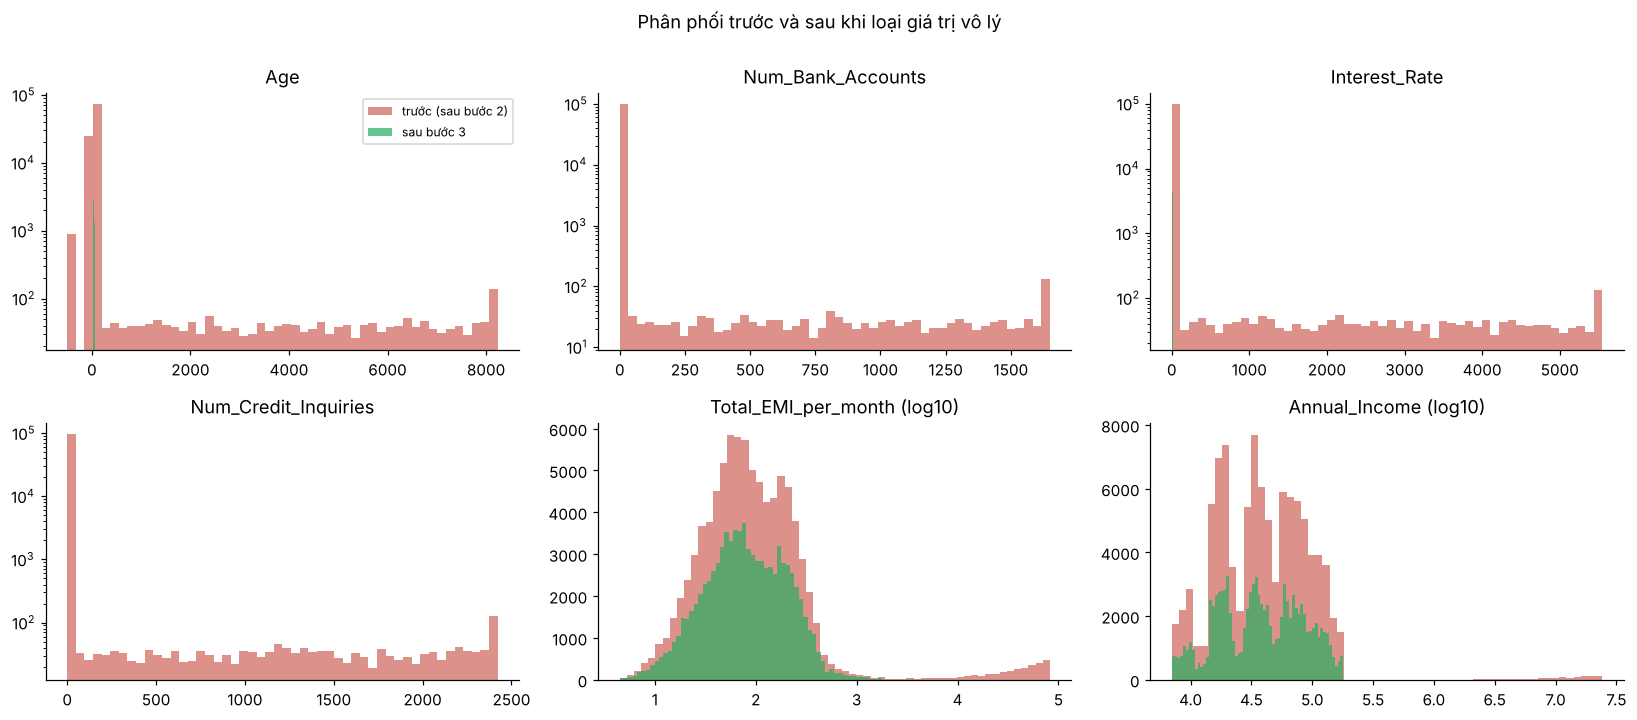

In [9]:
fig, ax = plt.subplots(2, 3, figsize=(15, 6.5))
for a, c in zip(ax.ravel(), ['Age', 'Num_Bank_Accounts', 'Interest_Rate', 'Num_Credit_Inquiries', 'Total_EMI_per_month', 'Annual_Income']):
    s_b = d2[c].dropna(); s_a = d3[c].dropna()
    if c in ('Total_EMI_per_month', 'Annual_Income'):
        a.hist(np.log10(s_b[s_b > 0]), bins=60, alpha=.55, color='#c0392b', label='trước (sau bước 2)'); a.hist(np.log10(s_a[s_a > 0]), bins=60, alpha=.7, color='#27ae60', label='sau bước 3'); a.set_title(c + ' (log10)')
    else:
        a.hist(s_b.clip(upper=s_b.quantile(.999)), bins=50, alpha=.55, color='#c0392b', label='trước (sau bước 2)'); a.hist(s_a, bins=50, alpha=.7, color='#27ae60', label='sau bước 3'); a.set_title(c); a.set_yscale('log')
ax[0, 0].legend(fontsize=8); plt.suptitle('Phân phối trước và sau khi loại giá trị vô lý', y=1.0); plt.tight_layout(); plt.show()

## Bước 4 – Sửa / điền thiếu: chọn chiến lược bằng thí nghiệm

Sau bước 3, mỗi cột còn các ô NaN (từ thiếu gốc, placeholder, giá trị vô lý). Câu hỏi: **điền bằng gì?** Câu trả lời phổ biến ("trung bình/trung vị toàn cột") bỏ qua cấu trúc *khách hàng × tháng* của dữ liệu. Notebook 1 gợi ý nhiều khả năng; ta **thử nghiệm để chọn**, không đoán.

### 4.1 Các chiến lược ứng viên
| Chiến lược | Ý tưởng | Hợp với |
|---|---|---|
| `global_median` / `global_mode` | giá trị phổ biến toàn bảng (đường cơ sở) | – |
| `cust_median` / `cust_mode` | giá trị đại diện của **chính khách đó** | cột hằng số theo khách |
| `nearest` | giá trị ở **tháng gần nhất** còn hợp lệ của khách | cột có "bước nhảy" thật |
| `interpolate` | nội suy tuyến tính theo tháng | cột đổi dần |
| `model` | mô hình học máy (HistGradientBoosting) dự đoán *giá trị* từ các cột khác của cùng dòng | cột phụ thuộc mạnh vào cột khác |
| `model_ratio` | như `model` nhưng dự đoán *tỷ lệ so với lương* (`cột / Monthly_Inhand_Salary`) rồi nhân lại | cột tiền tỷ lệ với thu nhập |

In [10]:
# ----------------------------------------------------------------------------------------------
# Bước 4: sửa / điền thiếu – các chiến lược dùng chung cho cả thí nghiệm và pipeline
# ----------------------------------------------------------------------------------------------
def nearest_fill(d, col):
    """Điền ô thiếu bằng giá trị ở tháng GẦN NHẤT (cùng khách hàng) còn hợp lệ; hòa thì lấy tháng trước.
    Phù hợp cột có 'bước nhảy' (số tài khoản, lương, EMI): không kéo giá trị của giai đoạn này sang giai đoạn khác."""
    t = pd.DataFrame({'c': d['Customer_ID'], 'm': d['Month_Num'], 'v': d[col]})
    t['vm'] = t['m'].where(t['v'].notna())
    g = t.groupby('c')
    prev_v, prev_m = g['v'].ffill(), g['vm'].ffill()
    next_v, next_m = g['v'].bfill(), g['vm'].bfill()
    d_prev, d_next = t['m'] - prev_m, next_m - t['m']
    use_prev = d_prev.notna() & (d_next.isna() | (d_prev <= d_next))
    return pd.Series(np.where(use_prev, prev_v, next_v), index=d.index).where(t['v'].isna(), t['v'])

def _cust_mode(s):
    m = s.dropna().mode()
    return m.iloc[0] if len(m) else np.nan

def payment_behaviour_code(d):
    """Mã hóa Payment_Behaviour thành số (NaN/Unknown có mã riêng) để dùng làm đặc trưng cho mô hình điền thiếu."""
    cats = sorted(d['Payment_Behaviour'].dropna().unique())
    return d['Payment_Behaviour'].map({c: i for i, c in enumerate(cats)}).fillna(-1)

def model_fill(d, col, features=MODEL_IMPUTE_FEATURES, seed=0, ratio=False):
    """Điền cột `col` bằng HistGradientBoostingRegressor học từ các cột còn lại của CÙNG dòng
    (Amount_invested_monthly và Monthly_Balance phụ thuộc mạnh vào lương và hành vi chi tiêu).
    ratio=True: dự đoán *tỷ lệ so với lương* (col / Monthly_Inhand_Salary) rồi nhân lại. Số tiền đầu tư / số dư tỷ lệ
    với thu nhập nên tỷ lệ ổn định hơn giữa các mức lương; trong thí nghiệm che giá trị (notebook 2, mục 4.2) cách này
    cho sai số thấp hơn dự đoán trực tiếp giá trị tuyệt đối, ở mọi mức lương."""
    X = d.assign(Payment_Behaviour_Code=payment_behaviour_code(d))[[f for f in features if f != col]]
    y = d[col]
    if ratio:
        scale = fill_numeric(d, 'Monthly_Inhand_Salary', 'nearest').clip(lower=1)
        for c in ('Amount_invested_monthly', 'Monthly_Balance', 'Total_EMI_per_month'):
            if c != col:
                X[c + '_to_salary'] = d[c] / scale
        X['Debt_to_Income'] = d['Outstanding_Debt'] / d['Annual_Income']
        y = y / scale
    known = y.notna()
    model = HistGradientBoostingRegressor(max_iter=300, random_state=seed).fit(X[known], y[known])
    pred = pd.Series(np.clip(model.predict(X), 0, None), index=d.index)
    if ratio:
        pred = pred * scale
    return d[col].where(d[col].notna(), pred)

def fill_numeric(d, col, strategy):
    """Trả về cột `col` đã điền theo `strategy` ∈ {global_median, cust_median, nearest, interpolate, model, model_ratio}."""
    s = d[col]
    if strategy == 'global_median':
        out = s.fillna(s.median())
    elif strategy == 'cust_median':
        out = s.fillna(d.groupby('Customer_ID')[col].transform('median'))
    elif strategy == 'nearest':
        out = nearest_fill(d, col)
    elif strategy == 'interpolate':
        out = d.groupby('Customer_ID')[col].transform(lambda x: x.interpolate(limit_direction='both'))
    elif strategy == 'model':
        out = model_fill(d, col)
    elif strategy == 'model_ratio':
        out = model_fill(d, col, ratio=True)
    else:
        raise ValueError(strategy)
    return out.fillna(s.median())          # dự phòng: khách không còn giá trị hợp lệ nào

def fill_categorical(d, col, strategy):
    """Trả về cột phân loại đã điền theo `strategy` ∈ {global_mode, cust_mode, nearest}."""
    s = d[col]
    if strategy == 'global_mode':
        out = s.fillna(_cust_mode(s))
    elif strategy == 'cust_mode':
        out = s.fillna(d.groupby('Customer_ID')[col].transform(_cust_mode))
    elif strategy == 'nearest':
        codes = s.astype('category')
        near = nearest_fill(d.assign(**{col: codes.cat.codes.replace(-1, np.nan)}), col)
        out = s.fillna(near.map(lambda x: codes.cat.categories[int(x)] if pd.notna(x) else np.nan))
    else:
        raise ValueError(strategy)
    return out.fillna(_cust_mode(s))

### 4.2 Thiết kế thí nghiệm "che giá trị"
Cách đo công bằng một phương pháp điền thiếu: lấy các ô **đã biết hợp lệ**, *che ngẫu nhiên 10%*, điền lại bằng từng chiến lược, rồi so với giá trị thật.
- Cột số: sai số tuyệt đối trung bình **chuẩn hóa theo độ lệch chuẩn của cột** (NMAE = MAE/σ; 0 là hoàn hảo, ~0,8 tương đương đoán bừa bằng trung vị) để so sánh được giữa các cột có đơn vị khác nhau.
- Cột phân loại: độ chính xác (tỷ lệ điền đúng).
- Lặp 3 hạt ngẫu nhiên khác nhau, lấy trung bình.

In [11]:
NUM_TEST = ['Annual_Income', 'Interest_Rate', 'Outstanding_Debt', 'Age', 'Num_Bank_Accounts', 'Num_Credit_Card', 'Total_EMI_per_month',
            'Monthly_Inhand_Salary', 'Num_Credit_Inquiries', 'Num_of_Delayed_Payment', 'Changed_Credit_Limit', 'Amount_invested_monthly', 'Monthly_Balance']
CAT_TEST = ['Occupation', 'SSN', 'Name', 'Credit_Mix', 'Payment_Behaviour']
CAND_NUM = ['global_median', 'cust_median', 'nearest', 'interpolate', 'model', 'model_ratio']
MONEY_COLS = ['Amount_invested_monthly', 'Monthly_Balance']      # chỉ hai cột tiền mới có ý nghĩa khi chia cho lương
CAND_CAT = ['global_mode', 'cust_mode', 'nearest']
SEEDS = (0, 1, 2)

def mask_cells(d, col, seed, frac=0.10):
    rng = np.random.default_rng(seed); known = d.index[d[col].notna()]
    idx = rng.choice(known, size=int(frac * len(known)), replace=False)
    m = d.copy(); m.loc[idx, col] = np.nan
    return m, idx

def eval_numeric(col):
    sd = d3[col].std(); res = {s: [] for s in CAND_NUM}
    for seed in SEEDS:
        m, idx = mask_cells(d3, col, seed); truth = d3.loc[idx, col]
        for s in CAND_NUM:
            if s == 'model_ratio' and col not in MONEY_COLS:
                continue
            res[s].append(((truth - fill_numeric(m, col, s).loc[idx]).abs().mean()) / sd)
    return {s: float(np.mean(v)) if v else np.nan for s, v in res.items()}

def eval_categorical(col):
    res = {s: [] for s in CAND_CAT}
    for seed in SEEDS:
        m, idx = mask_cells(d3, col, seed); truth = d3.loc[idx, col]
        for s in CAND_CAT:
            res[s].append(float((fill_categorical(m, col, s).loc[idx] == truth).mean()))
    return {s: float(np.mean(v)) for s, v in res.items()}

res_num = pd.DataFrame({c: eval_numeric(c) for c in NUM_TEST}).T[CAND_NUM]
res_cat = pd.DataFrame({c: eval_categorical(c) for c in CAT_TEST}).T[CAND_CAT]
print('Cột số – NMAE (thấp hơn là tốt hơn):'); display(res_num.round(4))
print('Cột phân loại – độ chính xác (cao hơn là tốt hơn):'); display(res_cat.round(3))

Cột số – NMAE (thấp hơn là tốt hơn):


,global_median,cust_median,nearest,interpolate,model,model_ratio
Annual_Income,0.7626,0.0000,0.0000,0.0000,0.0496,NaN
Interest_Rate,0.8290,0.0000,0.0000,0.0000,0.4056,NaN
Outstanding_Debt,0.7358,0.0000,0.0000,0.0000,0.3525,NaN
Age,0.8410,0.0196,0.0083,0.0086,0.6819,NaN
Num_Bank_Accounts,0.8356,0.0035,0.0013,0.0014,0.4673,NaN
Num_Credit_Card,0.8037,0.0042,0.0017,0.0017,0.5459,NaN
Total_EMI_per_month,0.6074,0.0649,0.0261,0.0255,0.2059,NaN
Monthly_Inhand_Salary,0.7623,0.0025,0.0010,0.0011,0.0345,NaN
Num_Credit_Inquiries,0.8368,0.1623,0.0669,0.0694,0.4261,NaN
Num_of_Delayed_Payment,0.8271,0.1208,0.1910,0.1810,0.4615,NaN


Cột phân loại – độ chính xác (cao hơn là tốt hơn):


,global_mode,cust_mode,nearest
Occupation,0.071,1.000,1.000
SSN,0.000,1.000,1.000
Name,0.000,1.000,1.000
Credit_Mix,0.455,1.000,1.000
Payment_Behaviour,0.277,0.258,0.231


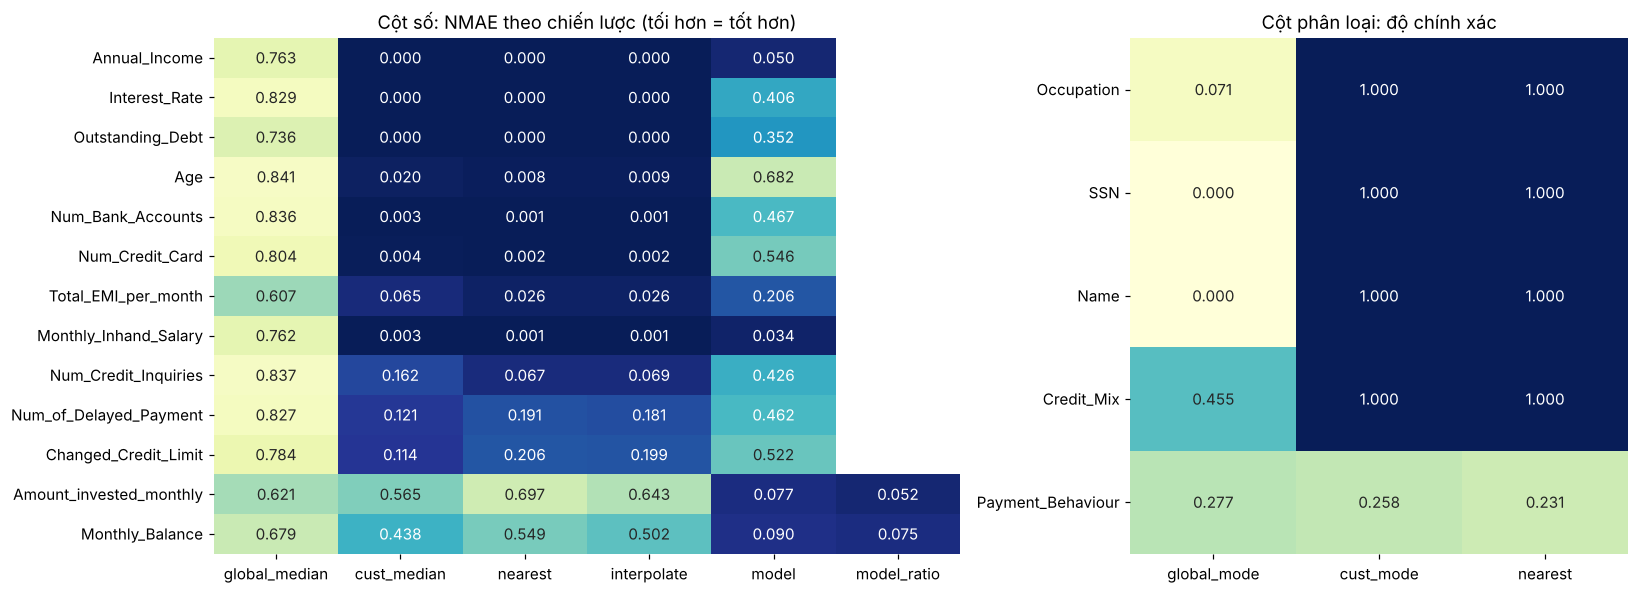

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={'width_ratios': [3, 2]})
sns.heatmap(res_num, annot=True, fmt='.3f', cmap='YlGnBu_r', ax=ax[0], cbar=False, vmax=0.9); ax[0].set_title('Cột số: NMAE theo chiến lược (tối hơn = tốt hơn)')
sns.heatmap(res_cat, annot=True, fmt='.3f', cmap='YlGnBu', ax=ax[1], cbar=False, vmin=0, vmax=1); ax[1].set_title('Cột phân loại: độ chính xác')
plt.tight_layout(); plt.show()

### 4.3 Chọn chiến lược theo luật rõ ràng
Với mỗi cột chọn chiến lược có NMAE thấp nhất; nếu nhiều chiến lược gần ngang nhau (chênh < 0,001) thì ưu tiên chiến lược **đơn giản hơn** theo thứ tự `cust_median` → `nearest` → `interpolate` → `model` → `model_ratio` → `global_median` (`model_ratio` chỉ thử cho hai cột tiền). Kết quả được **so với `REPAIR_PLAN`** đã khai báo trong module – nếu lệch thì dừng (assert).

In [13]:
PREF = ['cust_median', 'nearest', 'interpolate', 'model', 'model_ratio', 'global_median']
def pick(row, tol=0.001):
    best = row.min(); return next(s for s in PREF if row[s] <= best + tol)
found = res_num.apply(pick, axis=1)
planned = {c: strat for strat, cols in REPAIR_PLAN.items() for c in cols}
cmp = pd.DataFrame({'chiến lược tốt nhất (thí nghiệm)': found,
                    'NMAE tốt nhất': res_num.min(axis=1).round(4), 'NMAE điền trung vị toàn cục': res_num['global_median'].round(4),
                    'giảm sai số so với toàn cục': ((1 - res_num.min(axis=1) / res_num['global_median']) * 100).round(1).astype(str) + ' %',
                    'REPAIR_PLAN': pd.Series(planned).reindex(found.index)})
display(cmp)
assert (cmp['chiến lược tốt nhất (thí nghiệm)'] == cmp['REPAIR_PLAN']).all(), 'REPAIR_PLAN không khớp kết quả thí nghiệm'
print('REPAIR_PLAN khớp hoàn toàn với kết quả thí nghiệm ✓')

,chiến lược tốt nhất (thí nghiệm),NMAE tốt nhất,NMAE điền trung vị toàn cục,giảm sai số so với toàn cục,REPAIR_PLAN
Annual_Income,cust_median,0.0000,0.7626,100.0 %,cust_median
Interest_Rate,cust_median,0.0000,0.8290,100.0 %,cust_median
Outstanding_Debt,cust_median,0.0000,0.7358,100.0 %,cust_median
Age,nearest,0.0083,0.8410,99.0 %,nearest
Num_Bank_Accounts,nearest,0.0013,0.8356,99.8 %,nearest
Num_Credit_Card,nearest,0.0017,0.8037,99.8 %,nearest
Total_EMI_per_month,nearest,0.0255,0.6074,95.8 %,nearest
Monthly_Inhand_Salary,nearest,0.0010,0.7623,99.9 %,nearest
Num_Credit_Inquiries,nearest,0.0669,0.8368,92.0 %,nearest
Num_of_Delayed_Payment,cust_median,0.1208,0.8271,85.4 %,cust_median


REPAIR_PLAN khớp hoàn toàn với kết quả thí nghiệm ✓


**Đọc kết quả**
1. **Cột hằng số tuyệt đối** (`Annual_Income`, `Interest_Rate`, `Outstanding_Debt`): `cust_median` cho sai số **0,000** – khôi phục chính xác. Điền trung vị toàn cục sai tới ~0,74–0,83σ.
2. **Cột có bước nhảy thật** (`Num_Bank_Accounts`, `Num_Credit_Card`, `Age`, `Total_EMI_per_month`, `Monthly_Inhand_Salary`): `nearest` **tốt hơn** `cust_median` (sai số giảm khoảng một nửa trở lên), đúng như dự đoán ở notebook 1: mode của khách kéo giá trị giai đoạn này sang giai đoạn kia.
3. **Cột biến động mạnh**: `Num_of_Delayed_Payment` và `Changed_Credit_Limit` hợp `cust_median`; `Num_Credit_Inquiries` hợp `nearest` (có quán tính theo tháng).
4. **`Amount_invested_monthly` và `Monthly_Balance`**: các chiến lược dựa vào khách hàng gần như không hơn đường cơ sở (NMAE 0,44–0,70), nhưng **mô hình học máy giảm sai số còn ~0,05–0,09** – vì hai cột này phụ thuộc chặt vào lương và hành vi chi tiêu của *cùng dòng* (EDA 1.8). Đây là chỗ duy nhất đáng dùng mô hình. Trong hai dạng mô hình, **dự đoán tỷ lệ so với lương (`model_ratio`) thắng dự đoán giá trị tuyệt đối** ở cả hai cột (sai số giảm lần lượt 0,077 → 0,052 và 0,090 → 0,075). Lý do hợp lý: số tiền đầu tư và số dư tỷ lệ với thu nhập, nên tỷ lệ là đại lượng ổn định giữa các mức lương hơn; ở notebook 3 (mục 3.1) cách này cũng cho sai số thấp hơn riêng ở nhóm lương cao.
5. **Cột phân loại**: `SSN`, `Occupation`, `Name`, `Credit_Mix` – điền theo khách đạt độ chính xác ≈ **100%** (so với 0–46% nếu điền mode toàn cục).
6. **`Payment_Behaviour`: không chiến lược nào tốt hơn đoán** (độ chính xác ~0,23–0,28, ngang đoán theo tần suất). Đây là thói quen *thay đổi ngẫu nhiên theo tháng* nên các tháng khác không cho biết gì. Điền bừa chỉ tạo thêm nhiễu → **giữ thành một nhóm riêng `Unknown`** (7,6% dòng) để mô hình tự quyết định có dùng thông tin này không.

### 4.4 Hai trường hợp sửa bằng luật xác định (không cần ước lượng)

In [14]:
def parse_history_months(x):
    """'22 Years and 9 Months' -> 273 (tháng)."""
    m = re.match(r'(\d+) Years and (\d+) Months', str(x))
    return int(m.group(1)) * 12 + int(m.group(2)) if m else np.nan

def count_loan_types(x):
    """'Auto Loan, Credit-Builder Loan, and Home Equity Loan' -> 3;  NaN/'No Loan' -> 0."""
    if pd.isna(x) or x == 'No Loan':
        return 0
    return len([p for p in re.split(r',\s*', str(x).replace(' and ', ' ')) if p.strip()])

# (a) Num_of_Loan = số loại vay liệt kê trong Type_of_Loan
ok = d3.Num_of_Loan.notna()
cnt = d3.Type_of_Loan.map(count_loan_types)
print(f'(a) Num_of_Loan hợp lệ khớp số loại vay: {(cnt[ok] == d3.Num_of_Loan[ok]).mean():.2%} trên {ok.sum():,} dòng  → có thể suy ra Num_of_Loan chính xác')

# (b) Credit_History_Age: kiểm tra khả năng khôi phục bằng số học bằng cách che 10% rồi suy lại
hist = d3.Credit_History_Age.map(parse_history_months)
rng = np.random.default_rng(0); known = hist.index[hist.notna()]; idx = rng.choice(known, size=int(.1 * len(known)), replace=False)
h = hist.copy(); h.loc[idx] = np.nan
offset = (h - d3.Month_Num).groupby(d3.Customer_ID).transform('median')
pred = offset + d3.Month_Num
print(f'(b) Credit_History_Age: khôi phục đúng {(pred.loc[idx] == hist.loc[idx]).mean():.2%} ô bị che (sai số tuyệt đối tối đa {int((pred.loc[idx] - hist.loc[idx]).abs().max())} tháng)')

(a) Num_of_Loan hợp lệ khớp số loại vay: 100.00% trên 95,652 dòng  → có thể suy ra Num_of_Loan chính xác


(b) Credit_History_Age: khôi phục đúng 100.00% ô bị che (sai số tuyệt đối tối đa 0 tháng)


### 4.5 Áp dụng kế hoạch sửa lỗi
Hàm `repair` thực hiện toàn bộ kế hoạch đã được kiểm chứng: nhóm `Unknown` cho `Payment_Behaviour` → cột phân loại theo khách → số liệu theo `cust_median`/`nearest` → `Num_of_Loan` suy từ `Type_of_Loan` → `Credit_History_Age` đổi sang số tháng và suy ô thiếu → mô hình `model_ratio` cho hai cột còn lại (chạy **sau cùng** để dùng các cột đã sạch – kể cả lương – làm đặc trưng và mẫu số).

In [15]:
def repair(d, plan=REPAIR_PLAN, log=None):
    """Bước 4: sửa lỗi theo kế hoạch REPAIR_PLAN + các luật xác định (deterministic)."""
    d = d.copy()
    log = {} if log is None else log
    rep = log.setdefault('repaired', {})
    # --- Payment_Behaviour: ngẫu nhiên theo tháng, không chiến lược nào đoán tốt hơn ngẫu nhiên (notebook 2)
    #     => giữ thông tin "không rõ" bằng một nhóm riêng thay vì bịa giá trị
    rep['Payment_Behaviour'] = int(d['Payment_Behaviour'].isna().sum())
    d['Payment_Behaviour'] = d['Payment_Behaviour'].fillna('Unknown')
    # --- Type_of_Loan: ô trống = khách KHÔNG có khoản vay nào (thiếu đủ 8 tháng và Num_of_Loan = 0, EDA 1.3)
    #     => đây là một giá trị thật ('No Loan'), tuyệt đối không điền bằng giá trị phổ biến
    rep['Type_of_Loan'] = int(d['Type_of_Loan'].isna().sum())
    d['Type_of_Loan'] = d['Type_of_Loan'].fillna('No Loan')
    # --- Cột phân loại hằng số theo khách
    for col in plan['cust_mode']:
        n = int(d[col].isna().sum())
        d[col] = fill_categorical(d, col, 'cust_mode')
        rep[col] = n
    # --- Số liệu: median theo khách / tháng gần nhất
    for strat in ('cust_median', 'nearest'):
        for col in plan[strat]:
            n = int(d[col].isna().sum())
            d[col] = fill_numeric(d, col, strat)
            rep[col] = n
    # --- Luật xác định: Num_of_Loan = số loại vay liệt kê trong Type_of_Loan (khớp 100% ở dữ liệu hợp lệ)
    rep['Num_of_Loan'] = int(d['Num_of_Loan'].isna().sum())
    d['Num_of_Loan'] = d['Type_of_Loan'].map(count_loan_types)
    # --- Credit_History_Age: tăng đúng +1 tháng mỗi tháng => suy từ (giá trị − thứ tự tháng) của các tháng còn lại
    hist = d['Credit_History_Age'].map(parse_history_months)
    offset = (hist - d['Month_Num']).groupby(d['Customer_ID']).transform('median')
    rep['Credit_History_Age'] = int(hist.isna().sum())
    d['Credit_History_Months'] = hist.fillna(offset + d['Month_Num']).fillna(hist.median())
    d = d.drop(columns='Credit_History_Age')
    # --- Mô hình học máy (dự đoán tỷ lệ so với lương) cho hai cột phụ thuộc mạnh vào lương/hành vi chi tiêu
    for col in plan['model_ratio']:
        n = int(d[col].isna().sum())
        d[col] = fill_numeric(d, col, 'model_ratio')
        rep[col] = n
    return d

# ----------------------------------------------------------------------------------------------
# Bước 5 + pipeline tổng
# ----------------------------------------------------------------------------------------------
INT_COLS = ['Age', 'Num_Bank_Accounts', 'Num_Credit_Card', 'Interest_Rate', 'Num_of_Loan',
            'Num_of_Delayed_Payment', 'Num_Credit_Inquiries', 'Credit_History_Months', 'Month_Num']

def finalize(d):
    """Bước 5: ép kiểu cuối cùng và sắp xếp cột."""
    d = d.copy()
    for c in INT_COLS:
        d[c] = d[c].round().astype(int)
    order = ['ID', 'Customer_ID', 'Month', 'Month_Num', 'Name', 'Age', 'SSN', 'Occupation', 'Annual_Income',
             'Monthly_Inhand_Salary', 'Num_Bank_Accounts', 'Num_Credit_Card', 'Interest_Rate', 'Num_of_Loan',
             'Type_of_Loan', 'Delay_from_due_date', 'Num_of_Delayed_Payment', 'Changed_Credit_Limit',
             'Num_Credit_Inquiries', 'Credit_Mix', 'Outstanding_Debt', 'Credit_Utilization_Ratio',
             'Credit_History_Months', 'Payment_of_Min_Amount', 'Total_EMI_per_month', 'Amount_invested_monthly',
             'Payment_Behaviour', 'Monthly_Balance', 'Credit_Score']
    return d[[c for c in order if c in d.columns]]

d4 = repair(d3, log=LOG)
clean_df = finalize(d4)
rep = pd.DataFrame({'ô được sửa': LOG['repaired']})
rep['chiến lược'] = [planned.get(c, {'Payment_Behaviour': "nhóm 'Unknown'", 'Num_of_Loan': 'suy từ Type_of_Loan', 'Credit_History_Age': 'số học (offset theo tháng)',
                                     'Type_of_Loan': "'No Loan' (không có khoản vay)"}.get(c, '')) for c in rep.index]
rep['% dòng'] = (rep['ô được sửa'] / len(raw) * 100).round(2)
rep.sort_values('ô được sửa', ascending=False)

,ô được sửa,chiến lược,% dòng
Credit_Mix,20195,cust_mode,20.20
Monthly_Inhand_Salary,15002,nearest,15.00
Type_of_Loan,11408,'No Loan' (không có khoản vay),11.41
Name,9985,cust_mode,9.98
Credit_History_Age,9030,số học (offset theo tháng),9.03
Amount_invested_monthly,8784,model_ratio,8.78
Num_of_Delayed_Payment,8382,cust_median,8.38
Payment_Behaviour,7600,nhóm 'Unknown',7.60
Occupation,7062,cust_mode,7.06
SSN,5572,cust_mode,5.57


## Bước 5 – Kiểm tra sau làm sạch
### 5.1 Các ràng buộc phải thỏa
Hàm `validate_clean` kiểm tra 12 ràng buộc rút ra từ EDA (không còn thiếu/placeholder, mọi cột trong miền hợp lệ, hằng số theo khách đúng là hằng số, `Num_of_Loan` khớp `Type_of_Loan`, lịch sử tín dụng tăng đúng +1/tháng…).

In [16]:
def validate_clean(d):
    """Các kiểm tra ràng buộc sau làm sạch. Trả về dict {tên kiểm tra: True/False}."""
    g = d.groupby('Customer_ID')
    checks = {
        'Không còn ô thiếu': int(d.isna().sum().sum()) == 0,
        'Không còn placeholder': all((d[c].astype(str) != t).all() for c, t in PLACEHOLDERS.items() if c in d),
        'Mọi cột đếm nằm trong miền hợp lệ': all(d[c].between(lo, hi).all() for c, (lo, hi) in DOMAIN.items()),
        'EMI trong [0, 1800]': bool(d['Total_EMI_per_month'].between(0, EMI_MAX).all()),
        'Mỗi khách đúng 1 SSN / nghề / tên / Credit_Mix': all(g[c].nunique().eq(1).all()
                                                          for c in ['SSN', 'Occupation', 'Name', 'Credit_Mix']),
        'Mỗi khách 1 mức Annual_Income / Interest_Rate / Outstanding_Debt': all(g[c].nunique().eq(1).all()
                                                          for c in ['Annual_Income', 'Interest_Rate', 'Outstanding_Debt']),
        'Num_of_Loan = số loại vay': bool((d['Type_of_Loan'].map(count_loan_types) == d['Num_of_Loan']).all()),
        'Khách "No Loan" ⇔ Num_of_Loan = 0': bool(((d['Type_of_Loan'] == 'No Loan') == (d['Num_of_Loan'] == 0)).all()),
        'Tuổi trong 1 khách chênh tối đa 1': bool((g['Age'].max() - g['Age'].min()).le(1).all()),
        'Credit_History tăng đúng +1/tháng': bool((d['Credit_History_Months'] - d['Month_Num'])
                                                    .groupby(d['Customer_ID']).nunique().eq(1).all()),
        'Monthly_Balance & Amount_invested ≥ 0': bool((d[['Monthly_Balance', 'Amount_invested_monthly']] >= 0).all().all()),
        '8 dòng / khách, đúng thứ tự tháng': bool(g['Month_Num'].apply(lambda s: list(s) == list(range(1, 9))).all()),
    }
    return checks

checks = validate_clean(clean_df)
pd.Series(checks, name='đạt?').to_frame()

,đạt?
Không còn ô thiếu,True
Không còn placeholder,True
Mọi cột đếm nằm trong miền hợp lệ,True
"EMI trong [0, 1800]",True
Mỗi khách đúng 1 SSN / nghề / tên / Credit_Mix,True
Mỗi khách 1 mức Annual_Income / Interest_Rate / Outstanding_Debt,True
Num_of_Loan = số loại vay,True
"Khách ""No Loan"" ⇔ Num_of_Loan = 0",True
Tuổi trong 1 khách chênh tối đa 1,True
Credit_History tăng đúng +1/tháng,True


In [17]:
assert all(checks.values()), 'Có ràng buộc không đạt'
print('Tất cả', len(checks), 'ràng buộc đều đạt ✓')

Tất cả 12 ràng buộc đều đạt ✓


### 5.2 Báo cáo chất lượng dữ liệu: trước và sau

In [18]:
before = pd.read_csv('../data/reports/quality_before.csv', index_col=0)
rename = {'Credit_History_Age': 'Credit_History_Months'}
after_dtype = clean_df.dtypes.astype(str)
report = before[['dtype_goc', 'thieu', 'placeholder', 'vo_ly']].copy()
report.columns = ['dtype_trước', 'thiếu_trước', 'placeholder_trước', 'vô_lý_trước']
report['tổng_ô_lỗi_trước'] = report[['thiếu_trước', 'placeholder_trước', 'vô_lý_trước']].sum(axis=1)
report['ô_được_sửa'] = pd.Series(LOG['repaired']).reindex(report.index).fillna(0).astype(int)
report['dtype_sau'] = [after_dtype.get(rename.get(c, c), '') for c in report.index]
report['thiếu_sau'] = [int(clean_df[rename.get(c, c)].isna().sum()) for c in report.index]
report['placeholder_sau'] = [int((clean_df[c].astype(str) == PLACEHOLDERS[c]).sum()) if c in PLACEHOLDERS else 0 for c in report.index]
report = report[(report['tổng_ô_lỗi_trước'] > 0) | (report['dtype_trước'] != report['dtype_sau']) | (report['ô_được_sửa'] > 0)]
report.to_csv('../data/reports/data_quality_report.csv')
display(report)
tot_before = int(before[['thieu', 'placeholder', 'vo_ly']].sum().sum())
print(f'Tổng ô lỗi/thiếu/vô lý trước: {tot_before:,} ({tot_before / raw.size:.2%} số ô)  →  sau: {int(clean_df.isna().sum().sum()) + int(report.placeholder_sau.sum())}')

,dtype_trước,thiếu_trước,placeholder_trước,vô_lý_trước,tổng_ô_lỗi_trước,ô_được_sửa,dtype_sau,thiếu_sau,placeholder_sau
Name,str,9985,0,0,9985,9985,str,0,0
Age,str,0,0,2781,2781,2781,int64,0,0
SSN,str,0,5572,0,5572,5572,str,0,0
Occupation,str,0,7062,0,7062,7062,str,0,0
Annual_Income,str,0,0,999,999,999,float64,0,0
Monthly_Inhand_Salary,float64,15002,0,0,15002,15002,float64,0,0
Num_Bank_Accounts,int64,0,0,1345,1345,1345,int64,0,0
Num_Credit_Card,int64,0,0,2320,2320,2320,int64,0,0
Interest_Rate,int64,0,0,2034,2034,2034,int64,0,0
Num_of_Loan,str,0,0,4348,4348,4348,int64,0,0


Tổng ô lỗi/thiếu/vô lý trước: 126,926 (4.53% số ô)  →  sau: 0


In [19]:
# Nếu chọn xóa dòng lỗi thay vì sửa thì còn lại bao nhiêu?
bad_rows = d3.drop(columns=['Type_of_Loan']).isna().any(axis=1)      # Type_of_Loan trống = không có vay, không tính là lỗi
print(f'Dòng có ≥1 ô NaN sau bước 1–3 (thiếu / placeholder / vô lý): {bad_rows.sum():,} ({bad_rows.mean():.1%})')
print(f'→ nếu xóa dòng lỗi chỉ còn {(~bad_rows).sum():,} dòng ({(~bad_rows).mean():.1%}); số khách còn đủ cả 8 tháng: {int((~bad_rows).groupby(d3.Customer_ID).all().sum()):,} / 12,500')

Dòng có ≥1 ô NaN sau bước 1–3 (thiếu / placeholder / vô lý): 70,517 (70.5%)
→ nếu xóa dòng lỗi chỉ còn 29,483 dòng (29.5%); số khách còn đủ cả 8 tháng: 0 / 12,500


→ Xóa dòng lỗi sẽ **vứt hơn 70% dữ liệu** và phá vỡ cấu trúc 8 tháng/khách (không còn khách nào đủ 8 tháng). Sửa/khôi phục là lựa chọn duy nhất khả thi.

*Đối chiếu với notebook 1 (mục 1.9):* con số "76,3% dòng / 4,8% ô có vấn đề" ở đó đếm cả ô **chỉ sai định dạng** (số dính dấu `_`, như `'24_'` – loại lỗi này sửa được mà không mất thông tin ở Bước 2) và không tính `Type_of_Loan` trống (nghĩa là "không vay"). Ở đây ta đếm ô **thiếu / giả / vô lý**: 126.926 ô, trong đó 11.408 là `Type_of_Loan` trống được gán `No Loan`; và 70,5% dòng còn ít nhất một ô trống thật sau bước 1–3. Hai cách đếm khác định nghĩa nên con số khác nhau, không mâu thuẫn.

### 5.3 Trực quan hóa trước/sau

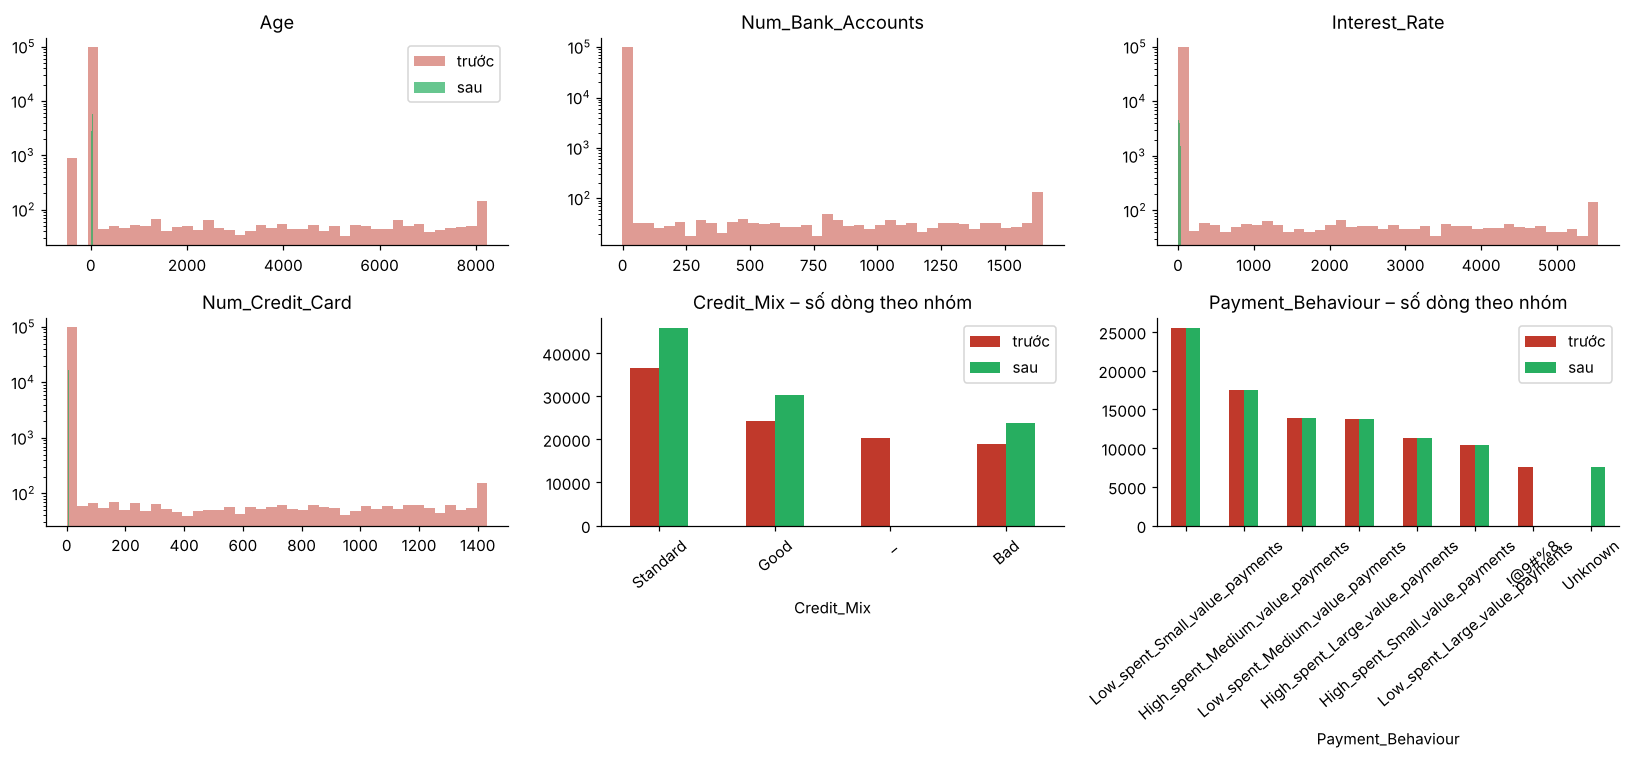

In [20]:
fig, ax = plt.subplots(2, 3, figsize=(15, 7))
for a, c in zip(ax.ravel()[:4], ['Age', 'Num_Bank_Accounts', 'Interest_Rate', 'Num_Credit_Card']):
    b = d2[c].dropna(); a.hist(b.clip(upper=b.quantile(.999)), bins=40, color='#c0392b', alpha=.5, label='trước'); a.hist(clean_df[c], bins=40, color='#27ae60', alpha=.7, label='sau'); a.set_yscale('log'); a.set_title(c)
ax[0, 0].legend()
for a, c in zip(ax.ravel()[4:], ['Credit_Mix', 'Payment_Behaviour']):
    pd.concat({'trước': raw[c].value_counts(), 'sau': clean_df[c].value_counts()}, axis=1).fillna(0).plot(kind='bar', ax=a, color=['#c0392b', '#27ae60'], rot=40); a.set_title(c + ' – số dòng theo nhóm')
plt.tight_layout(); plt.show()

In [21]:
# Mức độ thay đổi: bao nhiêu % ô của từng cột khác với bản gốc (sau khi đã ép kiểu)?
base = strip_numeric_text(add_month_num(raw)); base['Credit_History_Months'] = raw.Credit_History_Age.map(parse_history_months)
rows = []
for c in clean_df.columns:
    if c in base.columns and c not in ('Month_Num', 'Credit_Score'):
        same = (clean_df[c].astype(str).values == base[c].astype(str).values) if clean_df[c].dtype == object or str(clean_df[c].dtype) == 'str' else np.isclose(clean_df[c].astype(float), base[c].astype(float), equal_nan=True)
        rows.append({'cột': c, '% ô bị thay đổi': round((1 - np.mean(same)) * 100, 2)})
chg = pd.DataFrame(rows).set_index('cột').sort_values('% ô bị thay đổi', ascending=False)
chg[chg['% ô bị thay đổi'] > 0].T

cột,Credit_Mix,Monthly_Inhand_Salary,Type_of_Loan,Name,Credit_History_Months,Amount_invested_monthly,Num_of_Delayed_Payment,Payment_Behaviour,Occupation,SSN,Num_of_Loan,Num_Credit_Inquiries,Total_EMI_per_month,Age,Num_Credit_Card,Changed_Credit_Limit,Interest_Rate,Num_Bank_Accounts,Monthly_Balance,Annual_Income
% ô bị thay đổi,20.19,15.0,11.41,9.98,9.03,8.78,8.38,7.6,7.06,5.57,4.35,3.62,3.16,2.78,2.32,2.09,2.03,1.34,1.21,1.0


## Bước 6 – Kiểm tra tính nhất quán với module & xuất file
Notebook 3 và 4 dùng hàm `clean()` trong `src/credit_cleaning.py`. Kiểm tra kết quả của module **giống hệt** kết quả vừa tính trong notebook:

In [22]:
import credit_cleaning as cc
ref, ref_log = cc.clean(raw, return_log=True)
pd.testing.assert_frame_equal(clean_df.reset_index(drop=True), ref.reset_index(drop=True))
assert ref_log['repaired'] == LOG['repaired'] and ref_log['invalid'] == LOG['invalid'] and ref_log['placeholder'] == LOG['placeholder']
print('Kết quả notebook ≡ kết quả module (clean_df giống hệt từng ô) ✓')

Kết quả notebook ≡ kết quả module (clean_df giống hệt từng ô) ✓


In [23]:
clean_df.to_csv('../data/credit_clean.csv', index=False)
json.dump({k: {c: int(n) for c, n in v.items()} for k, v in LOG.items()}, open('../data/reports/cleaning_log.json', 'w'), ensure_ascii=False, indent=1)
print('Đã lưu: data/credit_clean.csv', clean_df.shape, '| data/reports/data_quality_report.csv | data/reports/cleaning_log.json')
clean_df.head(3).T

Đã lưu: data/credit_clean.csv (100000, 29) | data/reports/data_quality_report.csv | data/reports/cleaning_log.json


,0,1,2
ID,0x1602,0x1603,0x1604
Customer_ID,CUS_0xd40,CUS_0xd40,CUS_0xd40
Month,January,February,March
Month_Num,1,2,3
Name,Aaron Maashoh,Aaron Maashoh,Aaron Maashoh
Age,23,23,23
SSN,821-00-0265,821-00-0265,821-00-0265
Occupation,Scientist,Scientist,Scientist
Annual_Income,19114.12,19114.12,19114.12
Monthly_Inhand_Salary,1824.843333,1824.843333,1824.843333


In [24]:
# Từ điển dữ liệu của file sạch
pd.DataFrame({'dtype': clean_df.dtypes.astype(str), 'số giá trị khác nhau': clean_df.nunique(), 'min': clean_df.min(numeric_only=True), 'max': clean_df.max(numeric_only=True)})

,dtype,số giá trị khác nhau,min,max
Age,int64,43,14.000000,56.000000
Amount_invested_monthly,float64,99824,0.000000,1977.326102
Annual_Income,float64,12488,7005.930000,179987.280000
Changed_Credit_Limit,float64,4375,-6.490000,36.970000
Credit_History_Months,int64,404,1.000000,404.000000
Credit_Mix,str,3,NaN,NaN
Credit_Score,str,3,NaN,NaN
Credit_Utilization_Ratio,float64,100000,20.000000,50.000000
Customer_ID,str,12500,NaN,NaN
Delay_from_due_date,int64,73,-5.000000,67.000000


## Tổng kết & hạn chế

**Đã làm:** 5 loại lỗi được xử lý bằng 6 bước; mọi ngưỡng/chiến lược đều có bằng chứng (EDA) hoặc được chọn bằng thí nghiệm (che 10% giá trị); cuối cùng 12/12 ràng buộc kiểm tra đạt và file `credit_clean.csv` không còn ô thiếu.

**Điểm đáng nói nhất của quy trình:**
- Khai thác cấu trúc *khách hàng × tháng* thay vì thống kê toàn cục → khôi phục **chính xác** hầu hết cột hằng số.
- Phân biệt "bước nhảy thật" với lỗi → dùng *tháng gần nhất* thay vì mode.
- Biết **khi nào không nên điền** (`Payment_Behaviour` → `Unknown`).

**Hạn chế (cần nêu khi báo cáo):**
1. Thí nghiệm "che 10%" giả định ô thiếu thật xuất hiện ngẫu nhiên; EDA (mục 1.3) cho thấy gần đúng nhưng không chứng minh tuyệt đối.
2. `Amount_invested_monthly`, `Monthly_Balance` điền bằng mô hình nên là **ước lượng** (NMAE ≈ 0,05–0,07), không phải giá trị thật. Riêng `Monthly_Balance`: các ô thiếu thuộc một nhóm khách đặc biệt (lương cao, chi tiêu thấp) và hơn một nửa số ô điền rơi xuống mức sàn 0 – dấu hiệu thiếu không ngẫu nhiên, thí nghiệm "che 10%" **không đo được** sai số ở nhóm này (xem notebook 3, mục 3.1).
3. Các cột vốn không có "đáp án" (ví dụ ô `Monthly_Inhand_Salary` thiếu cả giai đoạn có bước nhảy) vẫn có thể sai ở các tháng chuyển đổi.
4. Miền hợp lệ lấy theo tần suất nên có thể loại nhầm vài giá trị thật hiếm ở sát biên (tối đa vài chục dòng, xem kiểm tra độ nhạy).
5. `Name` có nhiễu chữ cái cuối chưa sửa (không dùng làm đặc trưng).

→ **Notebook 3** kiểm định dữ liệu sạch (quan hệ với nhãn có được giữ không?) và tạo đặc trưng; **notebook 4** đo trực tiếp *làm sạch đóng góp bao nhiêu* cho mô hình.